# 07 — Analysis of EGFR Docking Results

## Project Overview

This notebook reads the docking outputs produced in notebook 06.
It does not repeat ligand preparation or AutoDock Vina.

The YY3 redocking RMSD is used as the protocol check. Candidate
scores are compared with that reference and with the predicted
pIC50 values from virtual screening. The best three poses are
then compared with the crystal YY3 contacts in the EGFR kinase site.

## Objectives

1. Load the docking scores, redocking RMSD table, and pose files.
2. Compare candidate Vina scores with the YY3 reference.
3. Compare docking scores with the machine-learning pIC50 predictions.
4. List protein residues within 4 Å of the top three poses and of YY3.
5. Draw the ten candidate structures with their scores.
6. Record which compounds are prioritized and what the scores do not show.

## Inputs

- `docking/results/candidate_docking_scores.csv`
- `docking/results/redocking/redocking_rmsd.csv`
- `docking/results/candidates/`
- `docking/results/redocking/YY3_redocked.pdbqt`
- `docking/input/YY3_reference_prepared.sdf`
- `docking/input/egfr_prepared.pdb`


## 1. Environment Setup and Library Imports

The analysis uses the saved tables, RDKit for poses and 2D drawings,
and Biopython for receptor coordinates. Random seeds are set so the
2D layout and any sampled operations stay repeatable.


In [1]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from Bio.PDB import PDBParser
from rdkit import Chem
from rdkit.Chem import Draw
from scipy.stats import pearsonr
from meeko import PDBQTMolecule, RDKitMolCreate

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

PROJECT_ROOT = Path("..").resolve()
DOCKING = PROJECT_ROOT / "docking"
RESULTS = DOCKING / "results"
FIGURES = PROJECT_ROOT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

CONTACT_CUTOFF = 4.0

print("Project directory:", PROJECT_ROOT)
print("Docking analysis environment ready.")


Project directory: /Users/gracescanlan/Desktop/egfr-ml-drug-discovery
Docking analysis environment ready.


## 2. Docking Results and Pose Files

The score table contains the YY3 reference, the original OpenBabel
protonation for every candidate, and the corrected states for two
compounds. The analysis uses one row per candidate: the neutral form
of ZINCpr00000m8N6T, the mono-protonated form of ZINCok00000rV1M6,
and the original OpenBabel state for the other eight. The RMSD table
contains all ten YY3 poses. Pose files for the selected states are
checked before any figure is drawn.


In [2]:
scores = pd.read_csv(RESULTS / "candidate_docking_scores.csv")
rmsd_table = pd.read_csv(RESULTS / "redocking" / "redocking_rmsd.csv")

analysis_state = {
    "ZINCpr00000m8N6T": "neutral",
    "ZINCok00000rV1M6": "mono",
}

def selected_for_analysis(row):
    if row.zincid == "YY3":
        return row.protonation_state == "reference"
    expected = analysis_state.get(row.zincid, "original_obabel")
    return row.protonation_state == expected

analysis_scores = scores[scores.apply(selected_for_analysis, axis=1)].copy()
candidates = analysis_scores[analysis_scores["zincid"] != "YY3"].copy()
reference = analysis_scores[analysis_scores["zincid"] == "YY3"].iloc[0]
yy3_score = float(reference["vina_score"])

def pose_path(row):
    if row.protonation_state in ("original_obabel", "reference"):
        stem = row.zincid
    else:
        stem = f"{row.zincid}_{row.protonation_state}"
    return RESULTS / "candidates" / f"{stem}.pdbqt"

pose_paths = {
    row.zincid: pose_path(row)
    for row in candidates.itertuples(index=False)
}
missing_poses = [zincid for zincid, path in pose_paths.items() if not path.exists()]

print("Score rows:", len(scores))
print("Rows used in the analysis:", len(analysis_scores))
print("Candidate poses:", len(pose_paths))
print("Missing pose files:", missing_poses)
print("YY3 reference score:", yy3_score)
print("Redocking poses:", len(rmsd_table))

display(analysis_scores.round(3))
display(rmsd_table.round(3))

assert len(candidates) == 10
assert not missing_poses
assert len(rmsd_table) == 10
assert (RESULTS / "redocking" / "YY3_redocked.pdbqt").exists()


Score rows: 14
Rows used in the analysis: 11
Candidate poses: 10
Missing pose files: []
YY3 reference score: -8.115
Redocking poses: 10


,zincid,canonical_smiles,vina_score,predicted_pIC50,rank,combined_score,max_training_similarity,protonation_state
0,YY3,C=CC(=O)Nc1cc(Nc2nccc(-c3cn(C)c4ccccc34)n2)c(O...,-8.115,NaN,NaN,NaN,NaN,reference
1,ZINCow00000g35fQ,CSCCNC(=O)C[C@H]1CCN(c2nc(C)nc3ccccc23)C1,-6.663,8.312,1.0,0.910,0.324,original_obabel
3,ZINCnG00000g0nB3,Oc1ccc(-c2cnc(Nc3ncnc4[nH]ccc34)s2)c(F)c1,-7.761,7.210,29.0,0.406,0.397,original_obabel
4,ZINCnc00000UlZfA,C[C@H](O)[C@H]1CCN1C(=O)[C@@H](C)NC(=O)c1ccc2c...,-7.257,7.369,6.0,0.334,0.271,original_obabel
5,ZINCpc000015MNGn,CCOC(=O)NCCNc1cc(N2CC(=O)N(C)[C@@H](C)C2)nc(C)n1,-6.541,7.308,16.0,0.299,0.269,original_obabel
6,ZINCmF000009qF0V,O=C(CCn1ncc2ccccc21)O[C@H]1CC2CCC1CC2,-7.223,7.298,18.0,0.293,0.268,original_obabel
7,ZINCpJ00000sUCKz,CC[C@@]1(C)CCCN(C(=O)Cn2cc(-c3cc(C)ccc3Cl)nn2)C1,-7.430,7.294,19.0,0.281,0.260,original_obabel
9,ZINCou00000pgX9h,COC(=O)[C@@]1(C)CCCCCN1C(=O)c1ccn2ncc(Br)c2n1,-5.163,7.312,15.0,0.265,0.240,original_obabel
10,ZINCp8000006CY2l,COC[C@@H](OC)C(=O)NCC[C@H]1CCCCN1c1nc(C)nc(=N)...,-6.105,7.360,7.0,0.260,0.215,original_obabel
11,ZINCpr00000m8N6T,CCc1nc([C@H](NCC(C)(C)[C@H](C)O)c2nnnn2CCSC)cs1,-5.604,8.201,2.0,0.677,0.186,neutral


,Pose,Vina score (kcal/mol),Heavy-atom RMSD (Å)
0,1,-8.115,0.747
1,2,-7.380,9.171
2,3,-7.353,2.203
3,4,-7.246,10.375
4,5,-7.217,7.521
5,6,-7.191,8.776
6,7,-7.179,8.489
7,8,-7.156,10.783
8,9,-7.134,8.144
9,10,-7.118,8.844


## 3. Docking Scores Relative to YY3

Candidate scores are plotted on the same axis as the YY3 redocking
score. A more negative Vina score is a more favorable score in
this setup. The reference line is the best noncovalent YY3 pose,
not an experimental affinity.


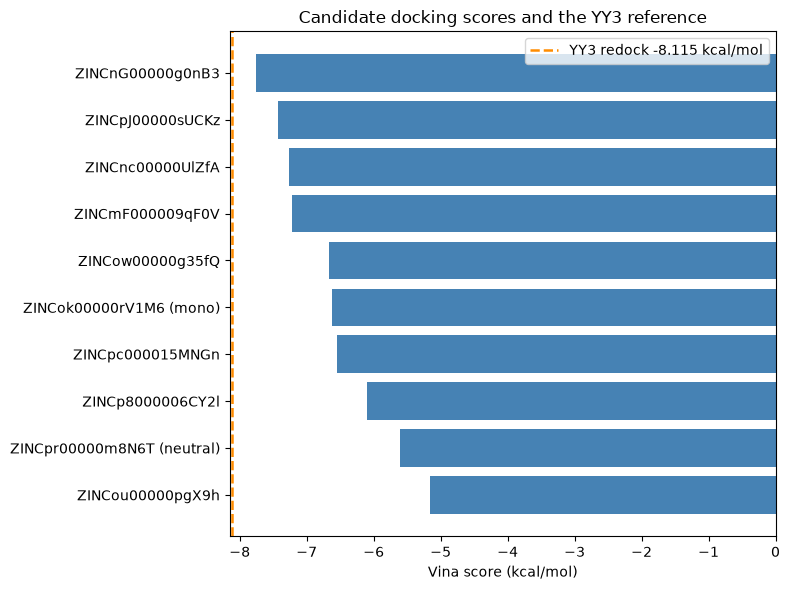

Figure saved: /Users/gracescanlan/Desktop/egfr-ml-drug-discovery/figures/docking_scores_vs_yy3.png
Best candidate: ZINCnG00000g0nB3
Candidates scoring better than YY3: 0


In [3]:
plot_scores = candidates.sort_values("vina_score", ascending=False).copy()
plot_scores["label"] = [
    f"{row.zincid} ({row.protonation_state})"
    if row.protonation_state in ("neutral", "mono")
    else row.zincid
    for row in plot_scores.itertuples(index=False)
]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(
    plot_scores["label"],
    plot_scores["vina_score"],
    color="steelblue",
)
ax.axvline(
    yy3_score,
    color="darkorange",
    linestyle="--",
    linewidth=1.8,
    label=f"YY3 redock {yy3_score:.3f} kcal/mol",
)
ax.set_xlabel("Vina score (kcal/mol)")
ax.set_ylabel("")
ax.set_title("Candidate docking scores and the YY3 reference")
ax.legend()

plt.tight_layout()
score_figure = FIGURES / "docking_scores_vs_yy3.png"
plt.savefig(score_figure, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", score_figure)
print("Best candidate:", candidates.loc[candidates["vina_score"].idxmin(), "zincid"])
print(
    "Candidates scoring better than YY3:",
    int((candidates["vina_score"] < yy3_score).sum()),
)


## 4. Docking Scores and Predicted pIC50

Each point is one of the ten screened candidates. Pearson's
correlation is calculated between the Vina score and the random
forest predicted pIC50.

A more favorable Vina score is more negative, while a more
favorable predicted potency is a larger pIC50. Agreement between
the two rankings would therefore appear as a negative correlation.
The correlation describes only these ten compounds. It is not an
experimental affinity, and it does not show that either calculation
is correct outside this shortlist.


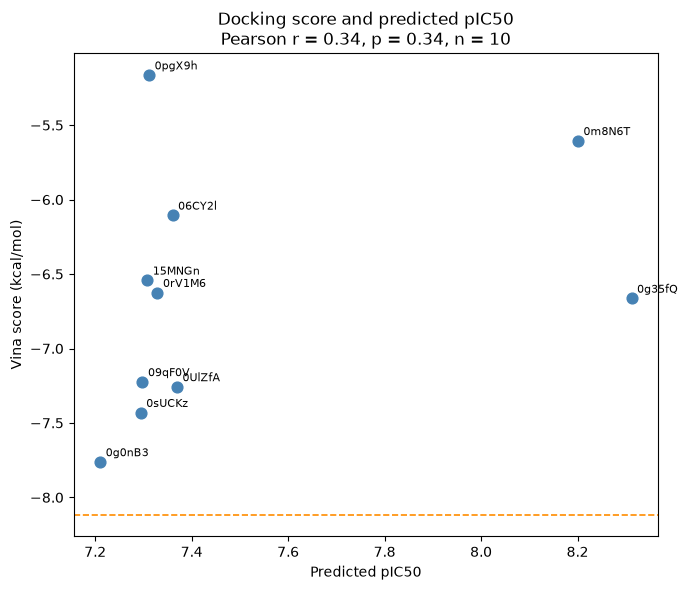

Figure saved: /Users/gracescanlan/Desktop/egfr-ml-drug-discovery/figures/docking_score_vs_predicted_pic50.png
Pearson r: 0.340
Two-sided p-value: 0.336
Sample size: 10


In [4]:
correlation, p_value = pearsonr(
    candidates["vina_score"],
    candidates["predicted_pIC50"],
)

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(
    candidates["predicted_pIC50"],
    candidates["vina_score"],
    s=60,
    color="steelblue",
)
for row in candidates.itertuples(index=False):
    ax.annotate(
        row.zincid[-6:],
        (row.predicted_pIC50, row.vina_score),
        textcoords="offset points",
        xytext=(4, 4),
        fontsize=8,
    )

ax.axhline(yy3_score, color="darkorange", linestyle="--", linewidth=1.2)
ax.set_xlabel("Predicted pIC50")
ax.set_ylabel("Vina score (kcal/mol)")
ax.set_title(
    f"Docking score and predicted pIC50\n"
    f"Pearson r = {correlation:.2f}, p = {p_value:.2f}, n = {len(candidates)}"
)

plt.tight_layout()
correlation_figure = FIGURES / "docking_score_vs_predicted_pic50.png"
plt.savefig(correlation_figure, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved:", correlation_figure)
print(f"Pearson r: {correlation:.3f}")
print(f"Two-sided p-value: {p_value:.3f}")
print("Sample size:", len(candidates))


## 5. Protein Contacts within 4 Å

Contacts are heavy-atom pairs no farther than 4 Å. The receptor
coordinates come from the prepared EGFR structure. Candidate
coordinates come from the best Vina pose. YY3 coordinates come
from the crystal ligand, which is the experimental pose recovered
by redocking.

A compound is marked as contacting MET793 or LYS745 when any of
its heavy atoms falls within the cutoff of that residue. MET793
is the hinge residue used here. LYS745 is the catalytic lysine.
The comparison with YY3 uses the same cutoff and receptor frame.


In [5]:
parser = PDBParser(QUIET=True)
structure = parser.get_structure(
    "egfr",
    DOCKING / "input" / "egfr_prepared.pdb",
)

protein_atoms = []
for atom in structure.get_atoms():
    if atom.element in ("H", "D"):
        continue
    residue = atom.get_parent()
    if residue.id[0] != " ":
        continue
    protein_atoms.append(atom)

protein_coords = np.array([atom.coord for atom in protein_atoms], dtype=float)


def heavy_atom_coords(mol, conf_id=0):
    heavy = Chem.RemoveHs(mol)
    conformer = heavy.GetConformer(conf_id)
    return np.array([
        [
            conformer.GetAtomPosition(i).x,
            conformer.GetAtomPosition(i).y,
            conformer.GetAtomPosition(i).z,
        ]
        for i in range(heavy.GetNumAtoms())
    ])


def residue_contacts(coords, cutoff=CONTACT_CUTOFF):
    distances = np.linalg.norm(
        protein_coords[:, None, :] - coords[None, :, :],
        axis=2,
    )
    minimum = distances.min(axis=1)
    contacts = {}
    for index in np.where(minimum <= cutoff)[0]:
        residue = protein_atoms[index].get_parent()
        key = (
            residue.get_parent().id,
            residue.get_resname(),
            int(residue.id[1]),
        )
        distance = float(minimum[index])
        if key not in contacts or distance < contacts[key]:
            contacts[key] = distance
    return contacts


def load_best_pose(path):
    poses = RDKitMolCreate.from_pdbqt_mol(
        PDBQTMolecule.from_file(str(path), skip_typing=True)
    )
    return poses[0]


crystal_yy3 = Chem.MolFromMolFile(
    str(DOCKING / "input" / "YY3_reference_prepared.sdf"),
    removeHs=False,
)
yy3_contacts = residue_contacts(heavy_atom_coords(crystal_yy3))
yy3_residue_ids = {
    f"{resname}{resnum}"
    for _, resname, resnum in yy3_contacts
}

top3 = candidates.sort_values(
    ["vina_score", "rank"],
    ascending=[True, True],
).head(3)

contact_rows = []

def append_contacts(zincid, pose_name, contacts):
    contacts_met793 = ("A", "MET", 793) in contacts
    contacts_lys745 = ("A", "LYS", 745) in contacts
    for (chain, resname, resnum), distance in sorted(
        contacts.items(),
        key=lambda item: (item[0][2], item[0][1]),
    ):
        residue_id = f"{resname}{resnum}"
        contact_rows.append({
            "zincid": zincid,
            "pose": pose_name,
            "chain": chain,
            "resname": resname,
            "resnum": resnum,
            "residue": residue_id,
            "min_distance_A": distance,
            "contacts_MET793": contacts_met793,
            "contacts_LYS745": contacts_lys745,
            "in_yy3_crystal_contacts": residue_id in yy3_residue_ids,
        })

append_contacts("YY3", "crystal", yy3_contacts)

pose_contacts = {}
for row in top3.itertuples(index=False):
    pose = load_best_pose(pose_paths[row.zincid])
    contacts = residue_contacts(heavy_atom_coords(pose, 0))
    pose_contacts[row.zincid] = contacts
    append_contacts(row.zincid, "best Vina pose", contacts)

contact_table = pd.DataFrame(contact_rows)
contact_path = RESULTS / "contact_analysis.csv"
contact_table.to_csv(contact_path, index=False)

summary_rows = []
for zincid, contacts in [("YY3", yy3_contacts), *pose_contacts.items()]:
    residue_ids = {f"{resname}{resnum}" for _, resname, resnum in contacts}
    summary_rows.append({
        "zincid": zincid,
        "n_residues": len(residue_ids),
        "contacts_MET793": ("A", "MET", 793) in contacts,
        "contacts_LYS745": ("A", "LYS", 745) in contacts,
        "shared_with_YY3": ", ".join(sorted(residue_ids & yy3_residue_ids)),
        "not_in_YY3": ", ".join(sorted(residue_ids - yy3_residue_ids)),
        "YY3_residues_absent": ", ".join(sorted(yy3_residue_ids - residue_ids)),
    })

contact_summary = pd.DataFrame(summary_rows)
display(contact_summary)
print("Contact table saved:", contact_path)
print("YY3 crystal residues:", ", ".join(sorted(yy3_residue_ids)))
print("MET793 minimum distance (Å):", round(yy3_contacts[("A", "MET", 793)], 3))
print("LYS745 in YY3 crystal contacts:", ("A", "LYS", 745) in yy3_contacts)


,zincid,n_residues,contacts_MET793,contacts_LYS745,shared_with_YY3,not_in_YY3,YY3_residues_absent
0,YY3,15,True,False,"ALA743, ASP800, GLN791, GLU804, GLY796, LEU100...",,
1,ZINCnG00000g0nB3,11,True,True,"ALA743, GLY796, LEU1001, LEU718, LEU792, LEU84...",LYS745,"ASP800, GLN791, GLU804, PHE723, SER797"
2,ZINCpJ00000sUCKz,11,True,True,"ALA743, GLN791, LEU718, LEU844, MET790, MET793...","ASP855, LYS745, THR854","ASP800, GLU804, GLY796, LEU1001, LEU792, PRO79..."
3,ZINCnc00000UlZfA,13,True,True,"ALA743, LEU718, LEU844, MET790, MET793, PHE723...","ARG841, ASN842, ASP855, GLU762, LYS745, THR854","ASP800, GLN791, GLU804, GLY796, LEU1001, LEU79..."


Contact table saved: /Users/gracescanlan/Desktop/egfr-ml-drug-discovery/docking/results/contact_analysis.csv
YY3 crystal residues: ALA743, ASP800, GLN791, GLU804, GLY796, LEU1001, LEU718, LEU792, LEU844, MET790, MET793, PHE723, PRO794, SER797, VAL726
MET793 minimum distance (Å): 2.932
LYS745 in YY3 crystal contacts: False


## 6. Candidate Structures

The ten candidate molecules are drawn in the protonation state used
for the reported score. ZINCpr00000m8N6T is neutral. ZINCok00000rV1M6
is mono-protonated on the N-ethyl piperazine nitrogen. The other
eight drawings use the canonical SMILES. Each legend shows the ZINC
identifier, the Vina score, and the predicted pIC50. These drawings
are not the docked three-dimensional poses.


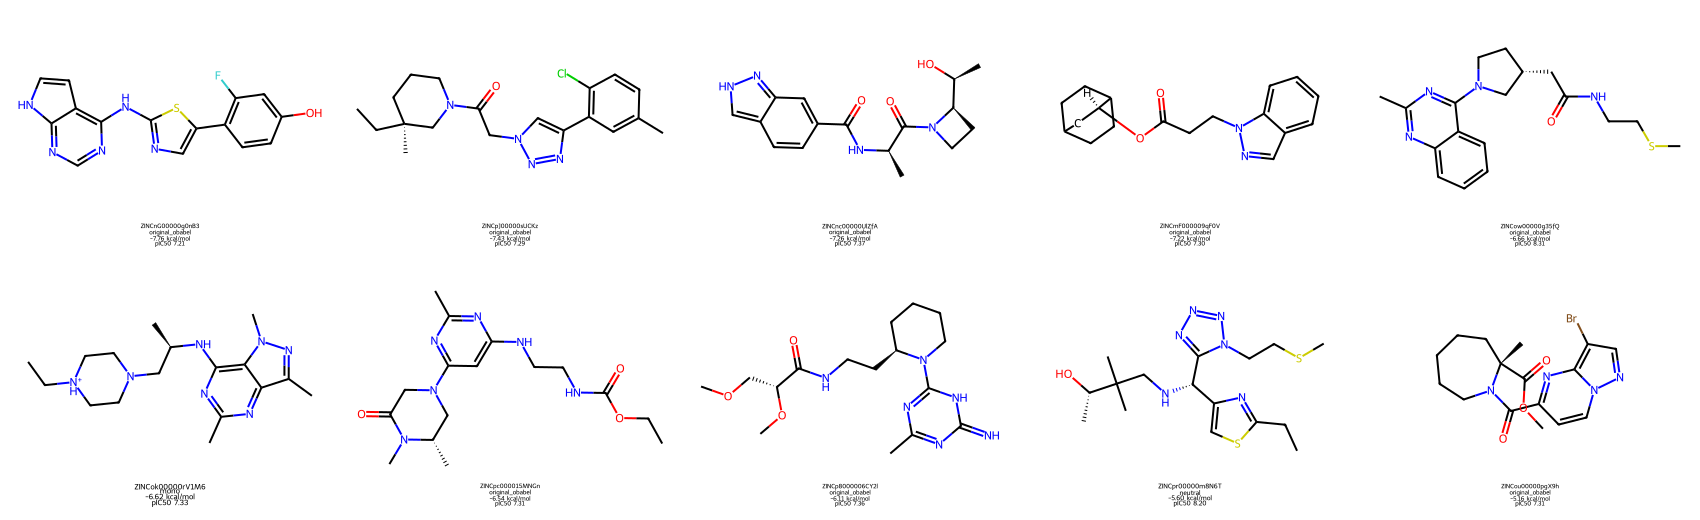

Figure saved: /Users/gracescanlan/Desktop/egfr-ml-drug-discovery/figures/candidate_2d_structures.png
Structures drawn: 10


In [6]:
def analysis_structure(row):
    smiles = row.canonical_smiles
    if row.zincid == "ZINCok00000rV1M6" and row.protonation_state == "mono":
        smiles = "CC[NH+]1CCN(C[C@@H](C)Nc2nc(C)nc3c(C)nn(C)c23)CC1"
    molecule = Chem.MolFromSmiles(smiles)
    if molecule is None:
        raise ValueError(f"Could not draw {row.zincid}")
    return molecule

drawing_table = candidates.sort_values("vina_score")
molecules = [analysis_structure(row) for row in drawing_table.itertuples(index=False)]
legends = [
    (
        f"{row.zincid}\n{row.protonation_state}\n"
        f"{row.vina_score:.2f} kcal/mol\npIC50 {row.predicted_pIC50:.2f}"
    )
    for row in drawing_table.itertuples(index=False)
]

structure_image = Draw.MolsToGridImage(
    molecules,
    molsPerRow=5,
    subImgSize=(340, 260),
    legends=legends,
    returnPNG=False,
)

structure_figure = FIGURES / "candidate_2d_structures.png"
structure_image.save(structure_figure)
display(structure_image)

print("Figure saved:", structure_figure)
print("Structures drawn:", len(molecules))


## 7. Conclusions

The YY3 redocking check succeeded on the criterion used in notebook 06.
The best pose scored -8.115 kcal/mol and its heavy-atom RMSD to the
crystal coordinates was 0.747 Å, below 2 Å. YY3 may bind covalently,
so this remains an approximate check of the noncovalent protocol.

The scores below use the neutral form of ZINCpr00000m8N6T and the
mono-protonated form of ZINCok00000rV1M6. Those states replace the
OpenBabel protonation, which had put a positive charge on the
secondary amine of ZINCpr00000m8N6T and a +2 charge on the piperazine
of ZINCok00000rV1M6. The other eight candidates are unchanged.

No candidate received a Vina score as favorable as YY3. The three
best candidate scores are:

| Compound | Vina score (kcal/mol) | ML rank | Predicted pIC50 | MET793 | LYS745 |
|---|---:|---:|---:|---|---|
| ZINCnG00000g0nB3 | -7.761 | 29 | 7.210 | yes | yes |
| ZINCpJ00000sUCKz | -7.430 | 19 | 7.294 | yes | yes |
| ZINCnc00000UlZfA | -7.257 | 6 | 7.369 | yes | yes |

All three contact the hinge residue MET793. The crystal YY3 pose
also contacts MET793, at a minimum heavy-atom distance of 2.93 Å.
YY3 does not contact LYS745 within 4 Å, while each of these three
poses does. ZINCnG00000g0nB3 shares the largest part of the YY3
contact pattern, including MET793, MET790, LEU792, and LEU844.

The Pearson correlation between Vina score and predicted pIC50 is
r = 0.34 (p = 0.34, n = 10). That association is weak. Agreement
between a more favorable docking score and a higher predicted
potency would appear as a negative correlation, because Vina scores
improve as they become more negative. The neutral form of
ZINCpr00000m8N6T, the second machine-learning rank, scores
-5.604 kcal/mol. ZINCow00000g35fQ, the first machine-learning rank,
scores -6.663 kcal/mol. The mono-protonated form of ZINCok00000rV1M6
scores -6.624 kcal/mol.

These scores rank poses inside one rigid receptor and one scoring
function. They do not measure experimental binding affinity or
EGFR inhibition. Receptor conformation, protonation, and the
inability of this Vina run to form a covalent bond can all change
the result.

For follow-up structural inspection, prioritize ZINCnG00000g0nB3,
then ZINCpJ00000sUCKz and ZINCnc00000UlZfA. The higher-ranked
machine-learning candidates remain ligand-based hypotheses, and
this docking setup did not give them scores close to YY3.
